In [1]:
from sklearn.metrics import fbeta_score, get_scorer, make_scorer
from sklearn.model_selection import ValidationCurveDisplay
from sklearn.model_selection import TimeSeriesSplit

## Fold composition checks for `StratifiedGroupKFold`

Customers appear in several rows, and a few customers have many rows. These checks show whether that makes the grouped folds uneven: fold sizes, the positive rate per fold, and how much of each validation fold comes from its single biggest customer. They are repeated for a few seeds, because which fold a big customer lands in depends on the shuffle.

In [2]:
import sys
from pathlib import Path

import pandas as pd

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

from main import load_config
from src.data import load_raw
from src.splitting import build_cv

cfg = load_config()
train = load_raw(cfg, "train_file")
test = load_raw(cfg, "test_file")
group_col = cfg["data"]["group_column"]
target_col = cfg["data"]["targets"]["classification"]
y, groups = train[target_col], train[group_col]

### Rows per customer

The biggest customers in train, compared with the expected fold size. If a customer had more rows than a fold, no grouped split could keep the folds balanced. The test column shows whether these customers come back in the test set.

In [3]:
rows_per_customer = train[group_col].value_counts()
fold_size = len(train) / cfg["cv"]["n_splits"]
print(f"{len(train)} rows, {rows_per_customer.size} customers, expected fold size ~{fold_size:.0f} rows")
print(rows_per_customer.describe().round(1).to_string())

top = rows_per_customer.head(5).rename("train_rows").to_frame()
top["share_of_train"] = (top["train_rows"] / len(train)).round(3)
top["share_of_one_fold"] = (top["train_rows"] / fold_size).round(3)
top["test_rows"] = test[group_col].value_counts().reindex(top.index, fill_value=0)
top

6534 rows, 610 customers, expected fold size ~1307 rows
count    610.0
mean      10.7
std       20.0
min        1.0
25%        1.0
50%        4.0
75%       12.0
max      277.0


,train_rows,share_of_train,share_of_one_fold,test_rows
customer_id,,,,
103940,277,0.042,0.212,0
258332,203,0.031,0.155,43
755628,112,0.017,0.086,15
519184,89,0.014,0.068,33
151492,89,0.014,0.068,9


### Validation folds for several seeds

Uses the project's own splitter (`build_cv`) with the config settings, only changing the seed. `biggest_customer_share` is the fraction of the validation fold that belongs to its largest customer.

In [4]:
def fold_summary(cfg, seed):
    """One row per validation fold: size, positive rate and the share of its biggest customer."""
    cv = build_cv({**cfg, "seed": seed})
    rows = []
    for fold, (_, val_idx) in enumerate(cv.split(train, y, groups)):
        val_groups = groups.iloc[val_idx].value_counts()
        rows.append({
            "seed": seed,
            "fold": fold,
            "size": len(val_idx),
            "customers": val_groups.size,
            "positive_rate": round(y.iloc[val_idx].mean(), 3),
            "biggest_customer": val_groups.index[0],
            "biggest_customer_rows": val_groups.iloc[0],
            "biggest_customer_share": round(val_groups.iloc[0] / len(val_idx), 3),
        })
    return rows

seeds = [cfg["seed"], 0, 1, 2]
folds = pd.DataFrame([row for seed in seeds for row in fold_summary(cfg, seed)])
print(f"overall positive rate: {y.mean():.3f}")
folds

overall positive rate: 0.559


,seed,fold,size,customers,positive_rate,biggest_customer,biggest_customer_rows,biggest_customer_share
0,42,0,1305,134,0.559,258332,203,0.156
1,42,1,1308,121,0.559,755628,112,0.086
2,42,2,1308,114,0.560,151492,89,0.068
3,42,3,1307,116,0.560,519184,89,0.068
4,42,4,1306,125,0.558,103940,277,0.212
5,0,0,1306,124,0.559,258332,203,0.155
6,0,1,1312,128,0.558,755628,112,0.085
7,0,2,1306,124,0.561,151492,89,0.068
8,0,3,1306,113,0.559,519184,89,0.068
9,0,4,1304,121,0.559,103940,277,0.212


In [5]:
# Range of each check across all folds and seeds
folds.groupby("seed")[["size", "positive_rate", "biggest_customer_share"]].agg(["min", "max"])

size       positive_rate        biggest_customer_share       
       min   max           min    max                    min    max
seed                                                               
0     1304  1312         0.558  0.561                  0.068  0.212
1     1305  1313         0.558  0.560                  0.068  0.212
2     1304  1315         0.558  0.560                  0.068  0.211
42    1305  1308         0.558  0.560                  0.068  0.212

## How stable is each validation design?

A design's job is to estimate how the pipeline does on new data, and a good design gives nearly the same estimate whatever its random seed. Each design below is run with `n_seeds` different seeds on the development rows (the locked holdout stays out), and we look at how much its estimate moves and what it costs.

All designs are grouped on `customer_id`, so a customer is never in training and validation at once:

- **StratifiedGroupKFold, 3 / 5 / 10 folds**: the project's splitter, which also keeps the positive rate similar across folds.
- **GroupKFold, 3 / 5 / 10 folds**: only balances the folds, without looking at the target.

More folds means each model trains on more rows, but each validation fold is smaller, so a single large customer weighs more in it.

The time-based designs (time holdout, `TimeSeriesSplit`) are left out: they use no seed, so they always give the same estimate and this test says nothing about them.

The model's own seed stays fixed at `cfg["seed"]`, so any spread comes from the design alone. The table also reports the std of the fold scores within one run, which shows how much individual folds disagree.

In [6]:
import time

import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import StratifiedGroupKFold, GroupKFold, TimeSeriesSplit, cross_val_score

from src.cleaning import clean, drop_duplicate_rows
from src.data import join_clientes, split_xyg
from src.models import build_pipeline
from src.splitting import split_holdout

# Same preparation as src/train.py, but keeping the purchase date so the rows can be ordered in time
df = drop_duplicate_rows(clean(load_raw(cfg, "train_file"), cfg), cfg["data"]["id_column"])
df = join_clientes(df, cfg)
X, y, groups = split_xyg(df, cfg, "classification")
dates = df[cfg["data"]["date_column"]]

dev_idx, _ = split_holdout(X, y, groups, cfg)
order = dates.iloc[dev_idx].sort_values(kind="stable").index  # dev rows, oldest first
X_dev, y_dev, g_dev, d_dev = (s.loc[order].reset_index(drop=True) for s in (X, y, groups, dates))
print(f"{len(X_dev)} development rows, {d_dev.min():%Y-%m-%d} to {d_dev.max():%Y-%m-%d}")

5229 development rows, 2015-07-11 to 2025-02-15


In [7]:
# Gap between the last training purchase and the first test purchase: the time CV should leave the same gap
date_col = cfg["data"]["date_column"]
train_dates = clean(load_raw(cfg, "train_file"), cfg)[date_col]
test_dates = clean(load_raw(cfg, "test_file"), cfg)[date_col]
train_test_gap = test_dates.min() - train_dates.max()
print(f"train: {train_dates.min():%Y-%m-%d} to {train_dates.max():%Y-%m-%d}")
print(f"test:  {test_dates.min():%Y-%m-%d} to {test_dates.max():%Y-%m-%d}")
print(f"gap between train and test: {train_test_gap.days} days")

train: 2015-07-11 to 2025-02-15
test:  2025-05-24 to 2026-10-06
gap between train and test: 98 days


In [8]:
def time_holdout(dates, val_size=0.2):
    """One (train, val) split: validation = purchases on or after the date that leaves `val_size` of rows."""
    cutoff = dates.quantile(1 - val_size)
    return [(np.flatnonzero(dates < cutoff), np.flatnonzero(dates >= cutoff))]


def repeated_stratified_group_kfold(X, y, groups, n_splits, n_repeats, seed):
    """
    All folds of `n_repeats` grouped `n_splits`-fold runs, each with its own shuffle. Repeat r of seed s uses
    random_state s * n_repeats + r, so different seeds never share a repeat.
    """
    return [fold
            for r in range(n_repeats)
            for fold in StratifiedGroupKFold(n_splits, shuffle=True, random_state=seed * n_repeats + r).split(X, y, groups)]


split = time_holdout(d_dev)[0]
print(f"time holdout: train {len(split[0])} rows up to {d_dev.iloc[split[0]].max():%Y-%m-%d}, "
      f"validate {len(split[1])} rows from {d_dev.iloc[split[1]].min():%Y-%m-%d}")
def time_series_split_gap(dates, n_splits, gap):
    """
    TimeSeriesSplit folds on date-sorted rows, minus the training rows dated less than `gap` before the
    fold's first validation date. TimeSeriesSplit's own `gap` counts rows, so the gap in days is applied here.
    """
    folds = []
    for tr, va in TimeSeriesSplit(n_splits).split(dates):
        val_start = dates.iloc[va].min()
        folds.append((tr[(dates.iloc[tr] <= val_start - gap).to_numpy()], va))
    return folds


for i, (tr, va) in enumerate(time_series_split_gap(d_dev, 5, train_test_gap)):
    print(f"time series fold {i}: train {len(tr)} rows up to {d_dev.iloc[tr].max():%Y-%m-%d}, "
          f"validate {len(va)} rows ({d_dev.iloc[va].min():%Y-%m-%d} to {d_dev.iloc[va].max():%Y-%m-%d}), "
          f"gap {(d_dev.iloc[va].min() - d_dev.iloc[tr].max()).days} days")

time holdout: train 4143 rows up to 2023-04-14, validate 1036 rows from 2023-04-15
time series fold 0: train 792 rows up to 2017-04-22, validate 871 rows (2017-07-29 to 2018-11-19), gap 98 days
time series fold 1: train 1609 rows up to 2018-08-10, validate 871 rows (2018-11-19 to 2020-07-18), gap 101 days
time series fold 2: train 2493 rows up to 2020-04-11, validate 871 rows (2020-07-18 to 2022-01-07), gap 98 days
time series fold 3: train 3281 rows up to 2021-10-01, validate 871 rows (2022-01-07 to 2023-09-23), gap 98 days
time series fold 4: train 4203 rows up to 2023-06-17, validate 871 rows (2023-09-23 to 2025-02-15), gap 98 days


"The difference between GroupKFold and StratifiedGroupKFold is that the former attempts to create balanced folds such that the number of distinct groups is approximately the same in each fold, whereas StratifiedGroupKFold attempts to create folds which preserve the percentage of samples from each class as much as possible given the constraint of non-overlapping groups between splits." https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html


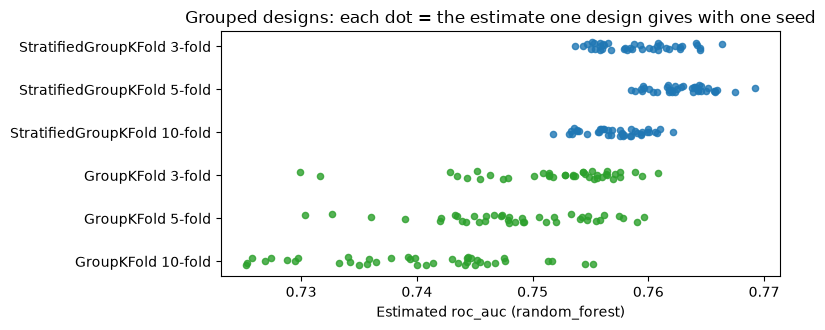

,fits,mean estimate,spread of the estimate (std over 40 seeds),std of fold scores (seed 0),seconds per run
design,,,,,
StratifiedGroupKFold 3-fold,3,0.7591,0.0034,0.0102,0.5490
StratifiedGroupKFold 5-fold,5,0.7630,0.0024,0.0340,0.9710
StratifiedGroupKFold 10-fold,10,0.7571,0.0025,0.0716,2.0741
GroupKFold 3-fold,3,0.7518,0.0067,0.0198,0.5655
GroupKFold 5-fold,5,0.7485,0.0068,0.0225,0.9550
GroupKFold 10-fold,10,0.7397,0.0082,0.0427,1.9637


In [9]:
metric = cfg["cv"]["metrics"][0]
n_seeds = 40
designs = {
    "StratifiedGroupKFold 3-fold": lambda s: StratifiedGroupKFold(3, shuffle=True, random_state=s),
    "StratifiedGroupKFold 5-fold": lambda s: StratifiedGroupKFold(5, shuffle=True, random_state=s),
    "StratifiedGroupKFold 10-fold": lambda s: StratifiedGroupKFold(10, shuffle=True, random_state=s),
    "GroupKFold 3-fold": lambda s: GroupKFold(3, shuffle=True, random_state=s),
    "GroupKFold 5-fold": lambda s: GroupKFold(5, shuffle=True, random_state=s),
    "GroupKFold 10-fold": lambda s: GroupKFold(10, shuffle=True, random_state=s)
}
pipe = build_pipeline("classification", cfg)
rows, estimates = [], {}
for name, make_splitter in designs.items():
    start = time.perf_counter()
    fold_scores = [cross_val_score(pipe, X_dev, y_dev, groups=g_dev, cv=make_splitter(s), scoring=metric)
                   for s in range(n_seeds)]
    seconds = (time.perf_counter() - start) / n_seeds
    est = [scores.mean() for scores in fold_scores]
    estimates[name] = est
    rows.append({"design": name, "fits": len(fold_scores[0]), "mean estimate": np.mean(est),
                 f"spread of the estimate (std over {n_seeds} seeds)": np.std(est, ddof=1),
                 "std of fold scores (seed 0)": np.std(fold_scores[0], ddof=1) if len(fold_scores[0]) > 1 else np.nan,
                 "seconds per run": seconds})

BLUE, GREEN = "#1f77b4", "#2ca02c"  # StratifiedGroupKFold, GroupKFold
rng = np.random.default_rng(cfg["seed"])
fig, ax = plt.subplots(figsize=(8, 3.4))
for i, (name, est) in enumerate(estimates.items()):
    ax.scatter(est, np.full(n_seeds, i) + rng.uniform(-0.1, 0.1, n_seeds), color=BLUE if name.startswith("Stratified") else GREEN, alpha=0.8, s=20)
ax.set_yticks(range(len(estimates)), list(estimates)); ax.invert_yaxis()
ax.set_xlabel(f"Estimated {metric} ({cfg['models']['classification']['type']})")
ax.set_title("Grouped designs: each dot = the estimate one design gives with one seed")
plt.tight_layout(); plt.show()
pd.DataFrame(rows).set_index("design").round(4)